<a href="https://colab.research.google.com/github/miriamamin1213-ux/Ablation_studies/blob/main/HECKTORDT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 27.7MB/s]


Dataset Shape: (588, 10)

Class Distribution
HPV_Label
0     58
1    530
Name: count, dtype: int64

================== FOLD 1/3 ==================
Selected parameters: {'ccp_alpha': 0.0, 'class_weight': {0: np.float64(5.0256410256410255), 1: np.float64(0.5552407932011332)}, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 10, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}
Validation metrics:
 fold                 1.000000
Accuracy             0.627551
Balanced_Accuracy    0.746803
Precision            0.981481
Recall               0.598870
F1                   0.743860
ROC_AUC              0.753643
PR_AUC               0.961107
Threshold            0.590000
dtype: float64
Confusion matrix:
 [[ 17   2]
 [ 71 106]]
Classification report:
               precision    recall  f1-score   support

           0       0.19      0.89     

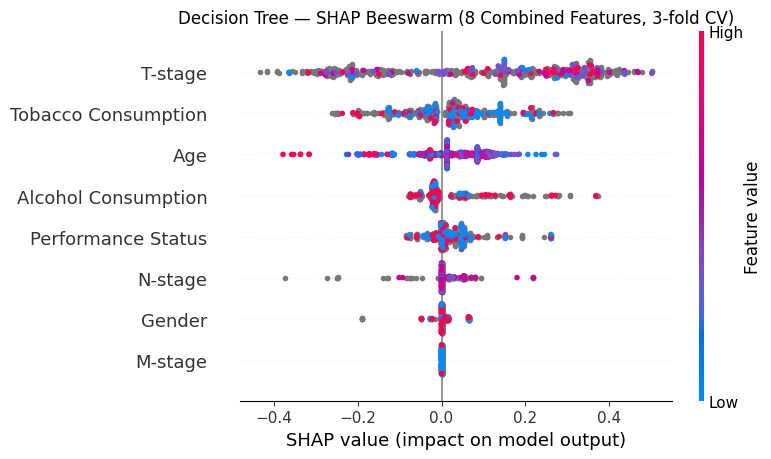

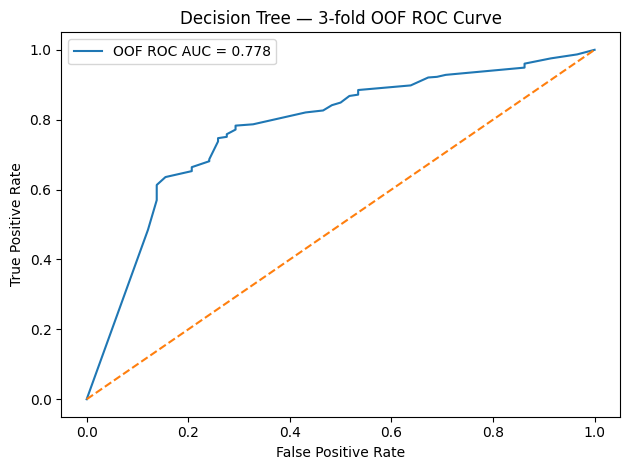

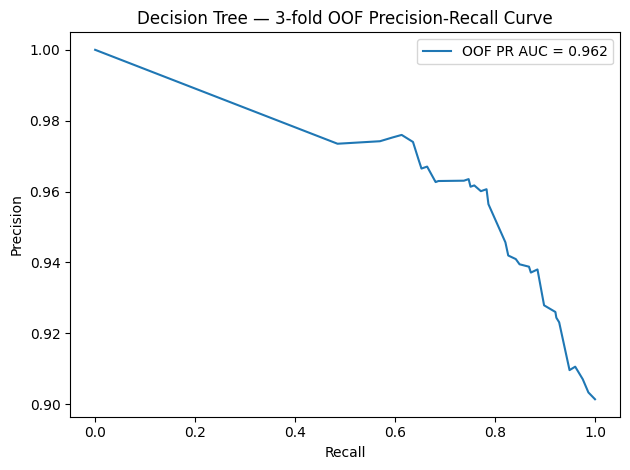

Saved results to: /content/drive/MyDrive/DT_results_HECKTOR_3fold


In [2]:
# ============================================================
# DECISION TREE — HECKTOR HPV CLASSIFIER
# Stratified 3-fold CV | Seed 42 | No test set | No SMOTE
# ============================================================

import os, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gdown
import shap
from lime.lime_tabular import LimeTabularExplainer

from google.colab import drive
from sklearn.model_selection import StratifiedKFold, ParameterGrid
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report, roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
drive.mount("/content/drive")

# 1. LOAD AND PREPARE DATA
gdown.download(
    id="1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv",
    output="HPV2025.xlsx",
    quiet=False
)
BASE = "/content/drive/MyDrive"
OUT_DIR = os.path.join(BASE, "DT_results_HECKTOR_3fold")
os.makedirs(OUT_DIR, exist_ok=True)
df = pd.read_excel("HPV2025.xlsx")
df = df.dropna(subset=["HPV Status"]).copy()
if "PatientID" in df.columns:
    df = df.rename(columns={"PatientID": "patient_id"})
else:
    df["patient_id"] = np.arange(len(df))
df["HPV_Label"] = pd.to_numeric(df["HPV Status"], errors="coerce")
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)

# SELECT EXACTLY EIGHT FEATURES
features = [
    "Age", "Gender", "Tobacco Consumption", "Alcohol Consumption",
    "Performance Status", "T-stage", "N-stage", "M-stage"
]
missing_features = [c for c in features if c not in df.columns]
if missing_features:
    raise KeyError(f"Missing predictor columns: {missing_features}")
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df = df[["patient_id"] + features + ["HPV_Label"]].copy()
print("Dataset Shape:", df.shape)
print("\nClass Distribution")
print(df["HPV_Label"].value_counts().sort_index())

# 2. THREE-FOLD CROSS-VALIDATION
numeric_features = ["Age"]
categorical_features = [c for c in features if c not in numeric_features]
grid = {
    "max_depth": [2, 3, 4, 5, 7, None],
    "min_samples_split": [2, 5, 10, 15],
    "min_samples_leaf": [2, 5, 10],
    "criterion": ["gini", "entropy"]
}
thresholds = np.linspace(0.10, 0.90, 81)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
fold_metrics, tuning_rows, oof_rows = [], [], []
fold_shap_values, fold_shap_data = [], []
fold_lime_importance, fold_importance = [], []
fold_models, fold_preprocessors = [], []
category_maps = {
    feature: {
        value: index for index, value in enumerate(
            sorted(df[feature].dropna().astype(str).unique())
        )
    }
    for feature in categorical_features
}

for fold, (train_idx, val_idx) in enumerate(
    cv.split(df[features], df["HPV_Label"]), start=1
):
    print(f"\n{'=' * 18} FOLD {fold}/3 {'=' * 18}")
    train = df.iloc[train_idx].copy()
    val = df.iloc[val_idx].copy()
    y_train = train["HPV_Label"].to_numpy()
    y_val = val["HPV_Label"].to_numpy()

    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

    preprocessor = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", encoder)
        ]), categorical_features)
    ])
    X_train = preprocessor.fit_transform(train[features])
    X_val = preprocessor.transform(val[features])
    feature_names = preprocessor.get_feature_names_out()
    counts = np.bincount(y_train, minlength=2)
    class_weights = {
        i: len(y_train) / (2 * counts[i]) for i in range(2)
    }

    best_model, best_threshold, best_key = None, 0.5, None
    for params in ParameterGrid(grid):
        candidate = DecisionTreeClassifier(
            **params, class_weight=class_weights, random_state=SEED
        )
        candidate.fit(X_train, y_train)
        val_prob = candidate.predict_proba(X_val)[:, 1]
        scores = [
            balanced_accuracy_score(y_val, (val_prob >= t).astype(int))
            for t in thresholds
        ]
        max_score = max(scores)
        threshold = min(
            (t for t, score in zip(thresholds, scores)
             if score == max_score),
            key=lambda t: abs(t - 0.5)
        )
        val_pred = (val_prob >= threshold).astype(int)
        auc = (
            roc_auc_score(y_val, val_prob)
            if len(np.unique(y_val)) == 2 else 0.5
        )
        pr_auc = average_precision_score(y_val, val_prob)
        key = (max_score, auc, pr_auc)
        tuning_rows.append({
            "fold": fold, **params,
            "validation_balanced_accuracy": max_score,
            "validation_roc_auc": auc,
            "validation_pr_auc": pr_auc,
            "threshold": float(threshold)
        })
        if best_key is None or key > best_key:
            best_key, best_model = key, candidate
            best_threshold = float(threshold)

    val_prob = best_model.predict_proba(X_val)[:, 1]
    val_pred = (val_prob >= best_threshold).astype(int)
    metrics = {
        "fold": fold,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Balanced_Accuracy": balanced_accuracy_score(y_val, val_pred),
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred, zero_division=0),
        "F1": f1_score(y_val, val_pred, zero_division=0),
        "ROC_AUC": (
            roc_auc_score(y_val, val_prob)
            if len(np.unique(y_val)) == 2 else np.nan
        ),
        "PR_AUC": average_precision_score(y_val, val_prob),
        "Threshold": best_threshold
    }
    fold_metrics.append(metrics)
    print("Selected parameters:", best_model.get_params())
    print("Validation metrics:\n", pd.Series(metrics))
    print("Confusion matrix:\n", confusion_matrix(y_val, val_pred))
    print("Classification report:\n",
          classification_report(y_val, val_pred, zero_division=0))
    oof_rows.append(pd.DataFrame({
        "fold": fold,
        "patient_id": val["patient_id"].to_numpy(),
        "y_true": y_val,
        "probability_positive": val_prob,
        "prediction": val_pred
    }))

    # Save fold model and preprocessing
    import joblib
    joblib.dump(best_model, os.path.join(OUT_DIR, f"fold_{fold}_model.joblib"))
    joblib.dump(
        preprocessor, os.path.join(OUT_DIR, f"fold_{fold}_preprocessor.joblib")
    )
    fold_models.append(best_model)
    fold_preprocessors.append(preprocessor)

    # Feature importance, grouped to the eight original predictors
    encoded_importance = pd.Series(
        best_model.feature_importances_, index=feature_names
    )
    grouped_importance = {}
    for feature in features:
        cols = [
            name for name in feature_names
            if name == f"num__{feature}" or name.startswith(f"cat__{feature}_")
        ]
        grouped_importance[feature] = (
            float(encoded_importance[cols].sum()) if cols else 0.0
        )
    fold_importance.append(grouped_importance)

    # Combine encoded-column SHAP values into the eight original features
    explainer = shap.TreeExplainer(best_model)
    shap_raw = explainer.shap_values(X_val)
    if isinstance(shap_raw, list):
        shap_matrix = np.asarray(shap_raw[1])
    else:
        shap_raw = np.asarray(shap_raw)
        shap_matrix = shap_raw[:, :, 1] if shap_raw.ndim == 3 else shap_raw
    shap_matrix = np.asarray(shap_matrix)
    if shap_matrix.ndim == 3:
        shap_matrix = shap_matrix[:, :, -1]
    grouped_shap = np.zeros((len(X_val), len(features)))
    grouped_data = pd.DataFrame(index=range(len(X_val)))
    for feature_idx, feature in enumerate(features):
        cols = [
            i for i, name in enumerate(feature_names)
            if name == f"num__{feature}" or name.startswith(f"cat__{feature}_")
        ]
        if cols:
            grouped_shap[:, feature_idx] = shap_matrix[:, cols].sum(axis=1)
        if feature in numeric_features:
            grouped_data[feature] = X_val[:, cols[0]] if cols else 0.0
        else:
            mode = train[feature].mode(dropna=True)
            fill_value = mode.iloc[0] if len(mode) else ""
            values = val[feature].fillna(fill_value).astype(str)
            grouped_data[feature] = values.map(category_maps[feature]).fillna(-1)
    fold_shap_values.append(grouped_shap)
    fold_shap_data.append(grouped_data[features])

    # LIME average absolute contribution per original predictor
    lime_explainer = LimeTabularExplainer(
        X_train, feature_names=list(feature_names),
        class_names=["HPV-negative", "HPV-positive"],
        mode="classification", discretize_continuous=True,
        random_state=SEED + fold
    )
    sample_n = min(50, len(X_val))
    sample_idx = np.linspace(0, len(X_val) - 1, sample_n, dtype=int)
    lime_scores = {feature: [] for feature in features}
    for row_idx in sample_idx:
        explanation = lime_explainer.explain_instance(
            X_val[row_idx],
            best_model.predict_proba,
            num_features=len(feature_names),
            labels=(1,)
        )
        for encoded_name, weight in explanation.as_list(label=1):
            matched = next(
                (feature for feature in features
                 if encoded_name.startswith(feature)),
                None
            )
            if matched is not None:
                lime_scores[matched].append(abs(float(weight)))
    fold_lime_importance.append({
        feature: (
            float(np.mean(values)) if values else 0.0
        ) for feature, values in lime_scores.items()
    })

# 3. CROSS-VALIDATION RESULTS
metrics_df = pd.DataFrame(fold_metrics)
metrics_df.to_csv(os.path.join(OUT_DIR, "fold_metrics.csv"), index=False)
summary = metrics_df.drop(columns=["fold"]).agg(["mean", "std"]).T
summary.to_csv(os.path.join(OUT_DIR, "metrics_mean_sd.csv"))
print("\nTHREE-FOLD METRICS (MEAN ± SD)\n", summary)
pd.DataFrame(tuning_rows).to_csv(
    os.path.join(OUT_DIR, "validation_tuning.csv"), index=False
)
oof = pd.concat(oof_rows, ignore_index=True)
oof.to_csv(os.path.join(OUT_DIR, "oof_predictions.csv"), index=False)
pd.DataFrame(fold_importance).agg(["mean", "std"]).T.to_csv(
    os.path.join(OUT_DIR, "feature_importance_mean_sd.csv")
)
pd.DataFrame(fold_lime_importance).agg(["mean", "std"]).T.to_csv(
    os.path.join(OUT_DIR, "lime_importance_mean_sd.csv")
)

# Mean absolute SHAP across folds for the eight combined original features
shap_fold_means = [
    dict(zip(features, np.abs(values).mean(axis=0)))
    for values in fold_shap_values
]
pd.DataFrame(shap_fold_means).agg(["mean", "std"]).T.to_csv(
    os.path.join(OUT_DIR, "shap_importance_mean_sd.csv")
)

# SHAP beeswarm with one combined row per original predictor
all_shap = np.vstack(fold_shap_values)
all_shap_data = pd.concat(fold_shap_data, ignore_index=True)[features]
shap.summary_plot(
    all_shap, all_shap_data, feature_names=features,
    plot_type="dot", show=False, max_display=len(features)
)
plt.title("Decision Tree — SHAP Beeswarm (8 Combined Features, 3-fold CV)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "shap_beeswarm.png"), dpi=180)
plt.show()

# ROC and precision-recall curves from pooled out-of-fold predictions
y_true = oof["y_true"].to_numpy()
oof_prob = oof["probability_positive"].to_numpy()
if len(np.unique(y_true)) == 2:
    fpr, tpr, _ = roc_curve(y_true, oof_prob)
    auc = roc_auc_score(y_true, oof_prob)
    plt.figure()
    plt.plot(fpr, tpr, label=f"OOF ROC AUC = {auc:.3f}")
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Decision Tree — 3-fold OOF ROC Curve")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "roc_curve_oof.png"), dpi=150)
    plt.show()
precision, recall, _ = precision_recall_curve(y_true, oof_prob)
pr_auc = average_precision_score(y_true, oof_prob)
plt.figure()
plt.plot(recall, precision, label=f"OOF PR AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Decision Tree — 3-fold OOF Precision-Recall Curve")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "pr_curve_oof.png"), dpi=150)
plt.show()

with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump({
        "model": "Decision Tree", "dataset": "HECKTOR", "seed": SEED,
        "features": features, "number_of_features": len(features),
        "target_column": "HPV Status", "folds": 3,
        "validation_selection": "balanced_accuracy, then ROC_AUC, then PR_AUC",
        "thresholds": [float(x) for x in thresholds],
        "class_weight": "computed separately from each training fold",
        "smote": False, "test_set": False,
        "shap_beeswarm_features": "eight original predictors; one row per predictor"
    }, f, indent=2)
print("Saved results to:", OUT_DIR)

